# Data exploration – NYC Airbnb 2019
Goal: understand the dataset before cleaning it. For each column, this notebook checks its type, missing values, unusual values and how useful it is for our question. Section 14 summarises the key findings and limitations, and proposes cleaning rules for team discussion.

## 1. Setup
Load the tools and the dataset: "New York City Airbnb Open Data" (AB_NYC_2019.csv) from Kaggle (Dgomonov, 2019). The original file is stored in our team's GitHub repository (data/raw), so the exploration and cleaning can be rerun from the same source.

In [64]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import haversine_distances
from matplotlib.colors import LogNorm

In [65]:
url = "https://raw.githubusercontent.com/aabouraya/airbnb-nyc-pricing-segments/refs/heads/main/data/raw/AB_NYC_2019.csv"
df = pd.read_csv(url)

## 2. First look at the data
Show the first five rows to check that the data loaded correctly.

In [66]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


**Findings**
- The data loaded correctly: all 16 columns are present and the values look plausible.
- Each row is one listing.
- Row 2 has 0 reviews, and its last_review and reviews_per_month are missing (NaN). The missing values may mean "no reviews yet" rather than errors. To be checked across the whole dataset.
- Row 4 has availability_365 = 0, even though it has reviews. It's unclear whether this means fully booked, blocked or inactive. To be checked.
- host_name contains personal names and isn't needed for our question.
- name is free text (the listing title).
- Prices in these five rows range from USD 80 to USD 225. The price distribution across all listings needs to be checked.

## 3. Size of the dataset
Check how many listings (rows) and columns the dataset has.

In [67]:
df.shape

(48895, 16)

**Finding:** The dataset has 48,895 listings (rows) and 16 columns, which matches the dataset on Kaggle.

## 4. Column types and missing values
Check the data type of each column and how many values are missing.

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

**Findings**
- 12 of the 16 columns have no missing values.
- name has 16 missing values and host_name has 21. These are text columns, so this is minor.
- last_review and reviews_per_month both have 10,052 missing values (about 21% of listings). The identical count suggests they are missing for the same listings, possibly those with no reviews. To be checked.
- last_review is stored as text (object), not as a date. It needs converting to a date before we can use it.
- All other columns have the expected types: numbers for prices, counts and coordinates, text for names and categories.

### 4.1 Missing review values
Check whether the listings with missing last_review and reviews_per_month are the ones with 0 reviews.

In [69]:
df[df["reviews_per_month"].isna()]["number_of_reviews"].value_counts()

,count
number_of_reviews,
0,10052


**Finding:** All 10,052 listings with a missing reviews_per_month have 0 reviews. This is consistent with the values being missing because there are no reviews yet, rather than being errors.

In [70]:
(df["last_review"].isna() == df["reviews_per_month"].isna()).all()

np.True_

**Finding:** last_review and reviews_per_month are missing for exactly the same listings.

In [71]:
(df["number_of_reviews"] == 0).sum()

np.int64(10052)

**Finding:** Exactly 10,052 listings have 0 reviews, the same number as the missing values. Together with the checks above, the missing values in last_review and reviews_per_month belong exactly to the listings without any reviews. They mean "no reviews yet", not errors.

## 5. Data quality checks
The info() check in section 4 only counts real missing values (NaN). This section checks for problems that look like normal values (inconsistent categories, placeholder text and duplicates), and whether the host information is consistent.

### 5.1 Categories
Check that the category columns (neighbourhood_group, room_type, neighbourhood) contain consistent values, without typos or placeholder entries.

In [72]:
df["neighbourhood_group"].value_counts()

,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373


**Finding:** neighbourhood_group contains exactly 5 values (Manhattan, Brooklyn, Queens, Bronx, Staten Island), with consistent spelling and no placeholder values. The groups are very unequal in size: Manhattan (21,661) and Brooklyn (20,104) together hold about 85% of all listings, while the Bronx (1,091) and Staten Island (373) hold only about 3%. Results for these two smaller groups will be less reliable.

In [73]:
df["room_type"].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


**Finding:** room_type contains exactly 3 values (Entire home/apt, Private room, Shared room), with consistent spelling and no placeholder values. Entire homes (25,409, about 52%) and private rooms (22,326, about 46%) make up almost all listings, while shared rooms are rare (1,160, about 2%).

In [74]:
df["neighbourhood"].nunique()

221

**Finding:** neighbourhood contains 221 different values, too many to check individually. The smallest neighbourhoods are examined next, as typos or unusual values would most likely appear among rarely used entries.

In [75]:
df["neighbourhood"].value_counts().tail(20)

,count
neighbourhood,
Arden Heights,4
Holliswood,4
Graniteville,3
Eltingville,3
Huguenot,3
Breezy Point,3
Neponsit,3
Co-op City,2
Westerleigh,2


**Finding:** The 20 smallest neighbourhoods all have plausible names, with no typos or placeholder values. "Bay Terrace, Staten Island" includes the neighbourhood group name, probably to distinguish it from a neighbourhood with the same name elsewhere (to be checked). Many neighbourhoods have very few listings (several have only 1), which is too few to draw reliable conclusions for those areas.

In [76]:
(df["neighbourhood"].value_counts() < 10).sum()

np.int64(53)

In [77]:
(df["neighbourhood"].value_counts() < 30).sum()

np.int64(106)

**Finding:** 53 of the 221 neighbourhoods (about 24%) have fewer than 10 listings, and 106 (about 48%) have fewer than 30. These thresholds are rough rules of thumb, but they show that many neighbourhoods are too small to learn reliable price patterns from. This is relevant when deciding how to use neighbourhood in the models.

In [78]:
df["neighbourhood"].value_counts().head(10)

,count
neighbourhood,
Williamsburg,3920
Bedford-Stuyvesant,3714
Harlem,2658
Bushwick,2465
Upper West Side,1971
Hell's Kitchen,1958
East Village,1853
Upper East Side,1798
Crown Heights,1564


**Finding:** The 10 largest neighbourhoods together hold 23,446 listings (about 48% of all listings), led by Williamsburg (3,920) and Bedford-Stuyvesant (3,714). Listings are therefore highly concentrated in a small number of neighbourhoods, while many others have very few.

In [79]:
df[df["neighbourhood"].str.contains("Bay Terrace")][["neighbourhood", "neighbourhood_group"]].value_counts()

,,count
neighbourhood,neighbourhood_group,
Bay Terrace,Queens,6
"Bay Terrace, Staten Island",Staten Island,2


**Finding:** Two different neighbourhoods share the name Bay Terrace: one in Queens (6 listings) and one in Staten Island (2 listings). The dataset distinguishes them by adding ", Staten Island" to the second one, so this is not an error.

### 5.2 Placeholder text
Check the text columns for words or symbols often used instead of a real missing value, such as "none", "n/a", "?" or empty text.

In [80]:
placeholders = ["", "nan", "none", "null", "n/a", "na", "n.a.", "-", "--", "?", "??", "unknown", "tbd"]
text_columns = ["name", "host_name", "neighbourhood_group", "neighbourhood", "room_type", "last_review"]

for col in text_columns:
    count = df[col].str.strip().str.lower().isin(placeholders).sum()
    print(col, count)

name 0
host_name 8
neighbourhood_group 0
neighbourhood 0
room_type 0
last_review 0


**Finding:** No placeholder values were found in name, neighbourhood_group, neighbourhood, room_type or last_review. host_name has 8 values matching the placeholder list. These are examined next, as some may be real names (e.g. "Na").

In [81]:
df[df["host_name"].str.strip().str.lower().isin(placeholders)]["host_name"].value_counts()

,count
host_name,
Nan,6
Na,2


**Finding:** The 8 matches in host_name are "Nan" (6) and "Na" (2). Both are capitalised like names and are plausible real first names, so they are most likely not placeholders. As host_name is not needed for the analysis, this has no impact.

### 5.3 Duplicates
Check whether any listing appears more than once, either with the same ID or with identical details under different IDs.

In [82]:
df["id"].duplicated().sum()

np.int64(0)

In [83]:
df.drop(columns=["id"]).duplicated().sum()

np.int64(0)

**Finding:** No duplicates were found: every listing ID is unique, and no two listings are identical in all other columns. Each row represents a distinct listing.

### 5.4 Hosts
Each host can have several listings, so host_id is expected to repeat. This checks how many different hosts there are, and whether calculated_host_listings_count matches the number of listings each host actually has in the data.

In [84]:
df["host_id"].nunique()

37457

**Finding:** The 48,895 listings belong to 37,457 different hosts, so some hosts have more than one listing.

In [85]:
actual_count = df.groupby("host_id")["id"].transform("count")
(actual_count != df["calculated_host_listings_count"]).sum()

np.int64(0)

**Finding:** calculated_host_listings_count matches the number of listings each host actually has in the dataset, for every listing. The column is consistent and can be relied on.

In [86]:
listings_per_host = df.groupby("host_id").size()
listings_per_host.value_counts().sort_index().head(10)

,count
1,32303
2,3329
3,951
4,360
5,169
6,95
7,57
8,52
9,26
10,21


In [87]:
print((listings_per_host >= 10).sum(), listings_per_host.max())

115 327


**Finding:** Most hosts have a single listing: 32,303 of 37,457 hosts (about 86%). 3,329 hosts (about 9%) have 2 listings, and the number of hosts falls quickly as the number of listings rises. Only 115 hosts have 10 or more listings, while the largest has 327. Hosts therefore range from single-listing hosts to hosts with several hundred listings.

In [88]:
host_size = pd.cut(df["calculated_host_listings_count"], bins=[0, 1, 9, 1000], labels=["1 listing", "2 to 9 listings", "10 or more listings"])
host_size.value_counts(normalize=True).sort_index().round(3)

,proportion
calculated_host_listings_count,
1 listing,0.661
2 to 9 listings,0.274
10 or more listings,0.065


**Finding:** Hosts with a single listing hold 66.1% of all listings, hosts with 2 to 9 listings hold 27.4%, and hosts with 10 or more listings hold 6.5%. Multi-listing hosts therefore account for a much larger share of listings than of hosts: hosts with 2 to 9 listings make up about 13% of hosts but hold more than a quarter of all listings, while the 115 hosts with 10 or more listings (about 0.3% of hosts) hold 6.5%. Whether results are reported per host or per listing therefore makes a considerable difference.

## 6. Overview of the numeric columns
Summary statistics for each numeric column: average, spread, minimum, maximum and quartiles.

In [89]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


**Findings**
- id and host_id are identifiers, so their statistics are not meaningful.
- latitude and longitude range from about 40.50 to 40.91 and -74.24 to -73.71. Whether this fits New York City is checked in sections 6.1 and 6.2.
- price: the median is USD 106, but the mean is USD 153, and the maximum is USD 10,000. A few very high prices pull the average up (right-skewed). The minimum is USD 0, which is implausible for a listing and needs checking.
- minimum_nights: the median is 3 nights and 75% of listings require 5 or fewer, but the maximum is 1,250 nights (over 3 years). Very high values need checking.
- number_of_reviews: the median is 5, but the maximum is 629, so this is also strongly skewed.
- reviews_per_month: the median is 0.72, but the maximum is 58.5 (almost two reviews a day). This looks unusually high and needs checking.
- calculated_host_listings_count: at least half of all listings belong to hosts with only 1 listing, but the maximum is 327 listings for one host.
- availability_365: at least 25% of listings show 0 days available, while the median is 45 days. What 0 means needs checking.

### 6.1 Distributions of the numeric columns
Histograms show how the values of each numeric column are distributed. id and host_id are left out, as they are identifiers and their distribution is not meaningful.

array([[<Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'price'}>],
       [<Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>, <Axes: >]],
      dtype=object)

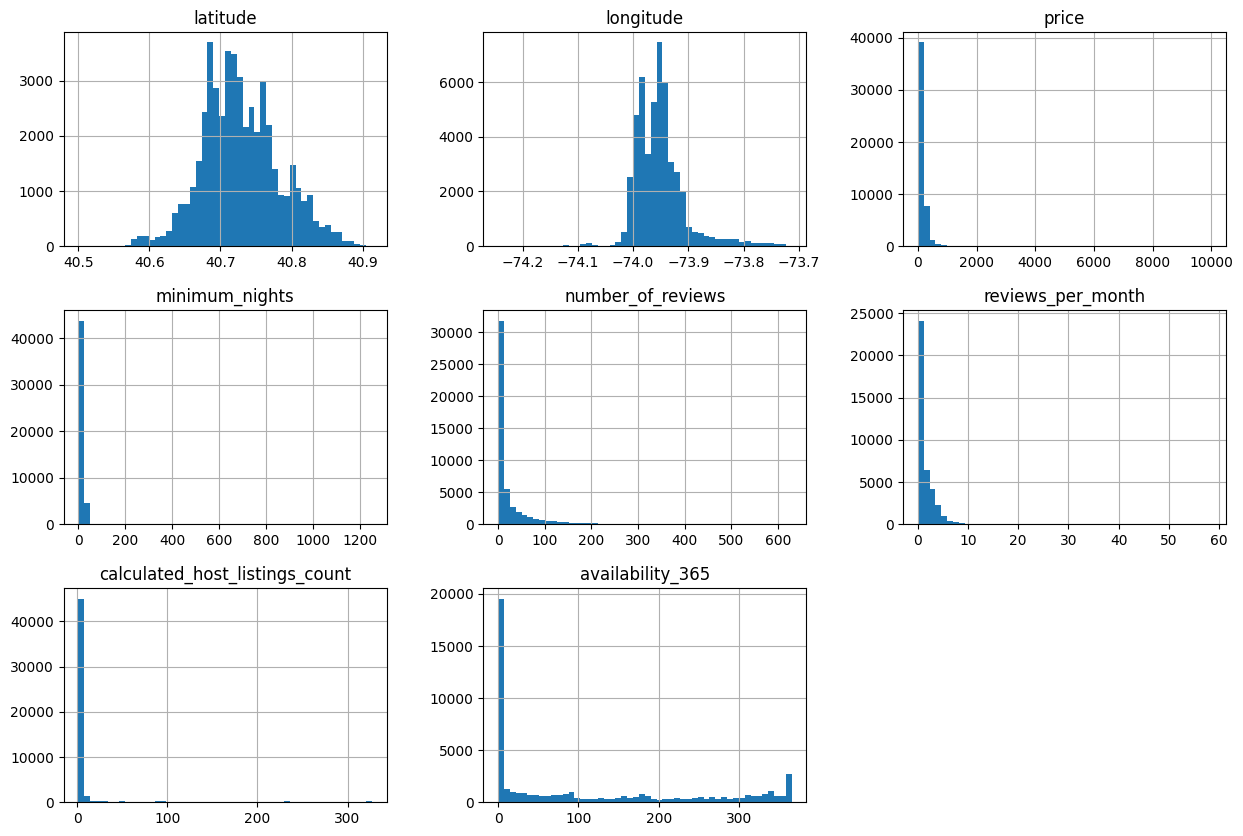

In [90]:
df.drop(columns=["id", "host_id"]).hist(figsize=(15, 10), bins=50)

**Findings**
- latitude ranges from about 40.50 to 40.91 and longitude from about -74.24 to -73.71. This falls within New York City's bounding box of latitude 40.498 to 40.915 and longitude -74.257 to -73.699 (New York City Department of City Planning, 2014), so no listings appear to be outside the city. Most listings are concentrated in a central range, with several peaks.
- price, minimum_nights, number_of_reviews, reviews_per_month and calculated_host_listings_count are strongly right-skewed: most listings have low values, while a few extreme values stretch the scale. Each of these needs a closer look with better scaling.
- availability_365 has two peaks: a very large one at 0 days (around 20,000 listings) and a smaller one at 365 days. What 0 means needs checking.
- calculated_host_listings_count shows small isolated bars at high values, which may be single hosts with many listings.

### 6.2 Location of the listings
Each listing is plotted as a dot using its coordinates and coloured by neighbourhood group, to check visually that the locations form the shape of New York City and to show where each neighbourhood group lies.

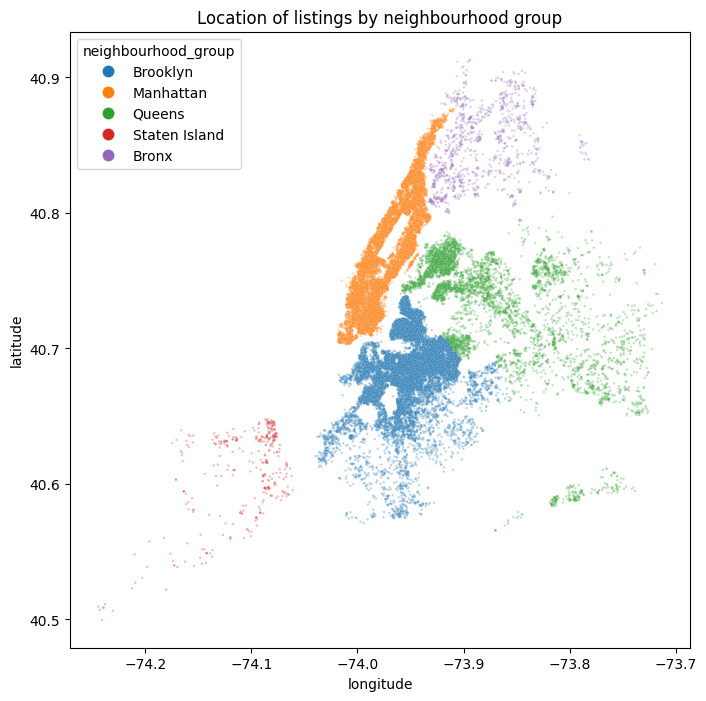

In [91]:
plt.figure(figsize=(8, 8))
ax = sns.scatterplot(data=df, x="longitude", y="latitude", hue="neighbourhood_group", s=3, alpha=0.3)
legend = ax.legend(title="neighbourhood_group", markerscale=5)
for handle in legend.legend_handles:
    handle.set_alpha(1)
plt.title("Location of listings by neighbourhood group")
plt.show()

**Finding:** The listings form the recognisable shape of New York City, with gaps where the rivers and bays are, and each neighbourhood group occupies its own distinct area: Manhattan a long, narrow strip in the centre, Brooklyn to the south of it, Queens to the east, the Bronx to the north and Staten Island in the south-west. Listings are most concentrated in Manhattan and the parts of Brooklyn closest to it, and sparse on Staten Island and in the outer parts of Queens and the Bronx. No listings appear in implausible locations, which confirms that the coordinates are plausible.

## 7. A closer look at price
Price is the value our regression model will predict. The summary statistics showed a minimum of USD 0 and a maximum of USD 10,000, and in the histogram almost all listings were squeezed into a few bars because of a few extreme values. This section examines low prices, high prices and the overall distribution in more detail.

### 7.1 Listings priced at USD 0
Check how many listings have a price of USD 0 and what they have in common.

In [92]:
(df["price"] == 0).sum()

np.int64(11)

**Finding:** 11 listings have a price of USD 0. A nightly price of USD 0 is not plausible, so these are likely data errors. Their details are examined next.

In [93]:
df[df["price"] == 0]

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
23161,18750597,"Huge Brooklyn Brownstone Living, Close to it all.",8993084,Kimberly,Brooklyn,Bedford-Stuyvesant,40.69023,-73.95428,Private room,0,4,1,2018-01-06,0.05,4,28
25433,20333471,★Hostel Style Room | Ideal Traveling Buddies★,131697576,Anisha,Bronx,East Morrisania,40.83296,-73.88668,Private room,0,2,55,2019-06-24,2.56,4,127
25634,20523843,"MARTIAL LOFT 3: REDEMPTION (upstairs, 2nd room)",15787004,Martial Loft,Brooklyn,Bushwick,40.69467,-73.92433,Private room,0,2,16,2019-05-18,0.71,5,0
25753,20608117,"Sunny, Quiet Room in Greenpoint",1641537,Lauren,Brooklyn,Greenpoint,40.72462,-73.94072,Private room,0,2,12,2017-10-27,0.53,2,0
25778,20624541,Modern apartment in the heart of Williamsburg,10132166,Aymeric,Brooklyn,Williamsburg,40.70838,-73.94645,Entire home/apt,0,5,3,2018-01-02,0.15,1,73
25794,20639628,Spacious comfortable master bedroom with nice ...,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68173,-73.91342,Private room,0,1,93,2019-06-15,4.28,6,176
25795,20639792,Contemporary bedroom in brownstone with nice view,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68279,-73.91170,Private room,0,1,95,2019-06-21,4.37,6,232
25796,20639914,Cozy yet spacious private brownstone bedroom,86327101,Adeyemi,Brooklyn,Bedford-Stuyvesant,40.68258,-73.91284,Private room,0,1,95,2019-06-23,4.35,6,222
26259,20933849,the best you can find,13709292,Qiuchi,Manhattan,Murray Hill,40.75091,-73.97597,Entire home/apt,0,3,0,NaN,NaN,1,0
26841,21291569,Coliving in Brooklyn! Modern design / Shared room,101970559,Sergii,Brooklyn,Bushwick,40.69211,-73.90670,Shared room,0,30,2,2019-06-22,0.11,6,333


**Finding:** Most of the 11 listings priced at USD 0 have reviews, several with many recent ones (up to 95, as recent as June 2019). This suggests they were active, paid listings, so a price of USD 0 is most likely a data error rather than a genuine price. Some hosts appear more than once (one host has 3 of these listings), and the listing IDs fall in a narrow range, which may point to a recording problem, though this cannot be confirmed from the data. As the true price is unknown, these listings cannot be used for price prediction.

### 7.2 Overall price distribution
Percentiles show where most prices lie and where the very high prices start.

In [94]:
df["price"].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])

,price
0.01,30.0
0.05,40.0
0.25,69.0
0.50,106.0
0.75,175.0
0.95,355.0
0.99,799.0


**Finding:** Most prices lie in a fairly narrow range: half of all listings cost USD 106 or less, the middle 50% cost between USD 69 and USD 175, and 98% cost between USD 30 and USD 799. The most expensive 1% of listings cost more than USD 799, up to USD 10,000, far above the rest. These very high prices need a closer look.

### 7.3 Very high prices
Count how many listings exceed different price levels, and examine the most expensive listings.

In [95]:
for limit in [500, 1000, 2000, 5000]:
    print(limit, (df["price"] > limit).sum())

500 1044
1000 239
2000 86
5000 20


**Finding:** Very high prices are rare: 1,044 listings (about 2.1%) cost more than USD 500 a night, 239 (about 0.5%) more than USD 1,000, 86 more than USD 2,000 and 20 more than USD 5,000. Whether these are genuine luxury listings or data errors needs to be checked.

In [96]:
df.sort_values("price", ascending=False).head(20)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
29238,22436899,1-BR Lincoln Center,72390391,Jelena,Manhattan,Upper West Side,40.77213,-73.98665,Entire home/apt,10000,30,0,NaN,NaN,1,83
9151,7003697,Furnished room in Astoria apartment,20582832,Kathrine,Queens,Astoria,40.76810,-73.91651,Private room,10000,100,2,2016-02-13,0.04,1,0
17692,13894339,Luxury 1 bedroom apt. -stunning Manhattan views,5143901,Erin,Brooklyn,Greenpoint,40.73260,-73.95739,Entire home/apt,10000,5,5,2017-07-27,0.16,1,0
6530,4737930,Spanish Harlem Apt,1235070,Olson,Manhattan,East Harlem,40.79264,-73.93898,Entire home/apt,9999,5,1,2015-01-02,0.02,1,0
40433,31340283,2br - The Heart of NYC: Manhattans Lower East ...,4382127,Matt,Manhattan,Lower East Side,40.71980,-73.98566,Entire home/apt,9999,30,0,NaN,NaN,1,365
12342,9528920,"Quiet, Clean, Lit @ LES & Chinatown",3906464,Amy,Manhattan,Lower East Side,40.71355,-73.98507,Private room,9999,99,6,2016-01-01,0.14,1,83
30268,23377410,Beautiful/Spacious 1 bed luxury flat-TriBeCa/Soho,18128455,Rum,Manhattan,Tribeca,40.72197,-74.00633,Entire home/apt,8500,30,2,2018-09-18,0.18,1,251
4377,2953058,Film Location,1177497,Jessica,Brooklyn,Clinton Hill,40.69137,-73.96723,Entire home/apt,8000,1,1,2016-09-15,0.03,11,365
29662,22779726,East 72nd Townhouse by (Hidden by Airbnb),156158778,Sally,Manhattan,Upper East Side,40.76824,-73.95989,Entire home/apt,7703,1,0,NaN,NaN,12,146
42523,33007610,70' Luxury MotorYacht on the Hudson,7407743,Jack,Manhattan,Battery Park City,40.71162,-74.01693,Entire home/apt,7500,1,0,NaN,NaN,1,364


**Finding:** The 20 most expensive listings (USD 5,100 to USD 10,000) are a mix. Some look implausible: private rooms priced at USD 6,500 to USD 10,000, and a price of USD 9,999 that appears three times and may be a placeholder. Several have very long minimum stays (30 to 180 nights), which may indicate monthly rather than nightly prices. Others are special uses rather than stays (a film location, a photo studio, Super Bowl event pricing). Some may be genuine luxury properties (townhouses, a yacht). Most have no or only old reviews, so it is unclear whether they were ever booked at these prices. Individual prices cannot be verified, so a general rule for very high prices is needed during cleaning.

### 7.4 Distribution without the extremes
Histograms of prices up to USD 1,000 and of the log of price, to see the shape of the distribution without a few extreme values dominating.

<Axes: >

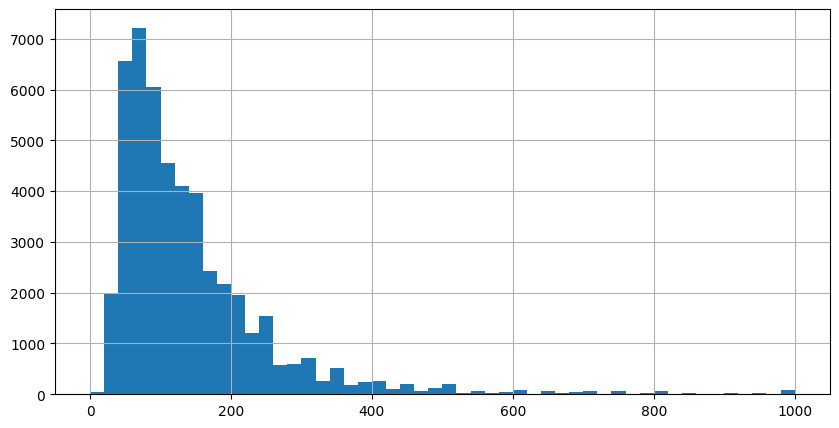

In [97]:
df[df["price"] <= 1000]["price"].hist(bins=50, figsize=(10, 5))

**Finding:** Looking only at listings up to USD 1,000 (about 99.5% of all listings), most prices lie between roughly USD 50 and USD 150 a night. The distribution is clearly right-skewed, with a long tail of more expensive listings, and shows small peaks at round prices (such as USD 250, USD 300, USD 500 and USD 1,000), suggesting hosts often choose round numbers.

<Axes: >

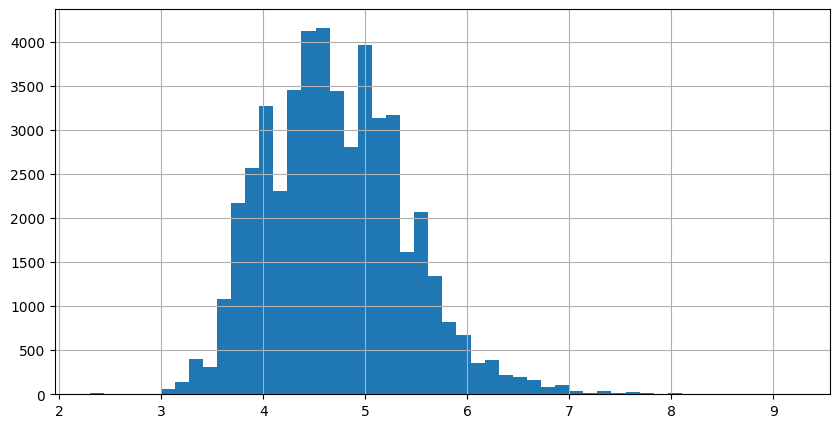

In [98]:
np.log(df[df["price"] > 0]["price"]).hist(bins=50, figsize=(10, 5))

**Finding:** On a log scale, the price distribution is roughly bell-shaped, centred around 4.6 to 4.7 (about USD 100 to USD 110), with most listings between about 3.7 and 6 (roughly USD 40 to USD 400). The extreme prices now have far less influence on the shape. This suggests that modelling the log of price is worth testing against modelling price directly, with both evaluated on the original dollar scale. The spikes at round prices remain visible.

## 8. A closer look at minimum_nights
The summary statistics showed a median of 3 nights but a maximum of 1,250 nights. This section examines how minimum stays are distributed and how many listings have very long ones.

### 8.1 Distribution of minimum stays
Percentiles and the most common values show how minimum stays are distributed.

In [99]:
df["minimum_nights"].quantile([0.5, 0.75, 0.9, 0.95, 0.99])

,minimum_nights
0.50,3.0
0.75,5.0
0.90,28.0
0.95,30.0
0.99,45.0


**Finding:** Most listings allow short stays: 75% require 5 nights or fewer. Between the 75th and 90th percentile, the minimum stay jumps to 28 nights, and 95% of listings require 30 nights or fewer. This suggests a separate group of listings aimed at stays of around a month. Only 1% of listings require more than 45 nights.

In [100]:
df["minimum_nights"].value_counts().head(15)

,count
minimum_nights,
1,12720
2,11696
3,7999
30,3760
4,3303
5,3034
7,2058
6,752
14,562


**Finding:** The most common minimum stays are 1, 2 and 3 nights (together about 66% of listings). 30 nights is the fourth most common value (3,760 listings, about 8%), and nearby values (28, 29, 31) also appear frequently, confirming a distinct group of listings aimed at month-long stays. Round periods such as 7 and 14 nights are also more common than neighbouring values.

### 8.2 Very long minimum stays
Count how many listings require very long minimum stays, and examine the most extreme ones.

In [101]:
for limit in [30, 90, 180, 365]:
    print(limit, (df["minimum_nights"] > limit).sum())

30 747
90 197
180 81
365 14


**Finding:** Few listings require stays longer than a month: 747 (about 1.5%) require more than 30 nights, 197 (about 0.4%) more than 90, 81 more than 180, and 14 more than a year. Minimum stays above a year are implausible for short-term rentals and may be errors or placeholder values.

In [102]:
df.sort_values("minimum_nights", ascending=False)[["name", "room_type", "price", "minimum_nights", "number_of_reviews", "last_review", "availability_365"]].head(15)

,name,room_type,price,minimum_nights,number_of_reviews,last_review,availability_365
5767,Prime W. Village location 1 bdrm,Entire home/apt,180,1250,2,2014-11-09,365
2854,NaN,Entire home/apt,400,1000,0,NaN,362
38664,Shared Studio (females only),Shared room,110,999,0,NaN,365
13404,Historic Designer 2 Bed. Apartment,Entire home/apt,99,999,2,2018-01-04,42
26341,Beautiful place in Brooklyn! #2,Private room,79,999,24,2018-06-28,249
7355,Beautiful Fully Furnished 1 bed/bth,Entire home/apt,134,500,30,2018-06-24,90
8014,Wonderful Large 1 bedroom,Entire home/apt,75,500,0,NaN,362
14285,Peaceful apartment close to F/G,Private room,45,500,0,NaN,358
47620,Williamsburg Apartment,Entire home/apt,140,500,0,NaN,331
11193,Zen Room in Crown Heights Brooklyn,Private room,50,500,10,2016-09-22,365


**Finding:** The 15 listings with the longest minimum stays (365 to 1,250 nights) show signs of placeholder values or non-standard use: 999 nights appears 3 times and 500 nights 5 times, and some titles indicate long-term rentals ("Lease Takeover", "16 month sublet") or unavailability ("Not available"). Most have no reviews or only old ones. Their prices are within the normal range, so the issue is the minimum stay rather than the price. These listings do not represent typical short-term rentals.

### 8.3 Minimum stay and price
Earlier sections suggested that some listings with long minimum stays may show a monthly rather than nightly price. This compares prices of listings requiring 30 or more nights with all other listings, within each room type.

In [103]:
df.groupby([df["minimum_nights"] >= 30, "room_type"])["price"].median().unstack()

room_type,Entire home/apt,Private room,Shared room
minimum_nights,,,
False,160.0,70.0,50.0
True,170.0,53.0,35.0


**Finding:** Within each room type, listings requiring 30 or more nights have median prices similar to or lower than other listings (entire homes USD 170 vs USD 160, private rooms USD 53 vs USD 70, shared rooms USD 35 vs USD 50). If monthly prices had commonly been entered as nightly prices, these medians would be several times higher. The suspicion from earlier sections therefore does not hold for long-stay listings in general, although it may still apply to a few individual listings. Long-stay listings appear to be priced per night, sometimes at a lower rate.

## 9. A closer look at availability_365
The summary statistics and histogram showed that many listings have 0 days available, and another group is available all year. This section examines what 0 days available might mean.

### 9.1 Listings with 0 days available
Count the listings with 0 days available and check when they were last reviewed.

In [104]:
(df["availability_365"] == 0).sum()

np.int64(17533)

**Finding:** 17,533 listings (about 36%) have 0 days available. This could mean they are fully booked, blocked by the host or inactive. As this affects more than a third of the data, the meaning of 0 needs to be examined further.

In [105]:
zero_avail = df[df["availability_365"] == 0]
pd.to_datetime(zero_avail["last_review"]).dt.year.value_counts(dropna=False).sort_index()

,count
last_review,
2011.0,3
2012.0,10
2013.0,25
2014.0,147
2015.0,1211
2016.0,2323
2017.0,2530
2018.0,3351
2019.0,3088


**Finding:** Of the 17,533 listings with 0 days available, 3,088 were last reviewed in 2019, which indicates recent guest activity; for them, 0 may mean fully booked or temporarily closed. 6,249 were last reviewed before 2018 and 4,845 have never been reviewed. These patterns are consistent with possible inactivity, although the dataset cannot distinguish inactive listings from listings with blocked or fully booked calendars. A further 3,351 were last reviewed in 2018 and are harder to interpret. 0 days available therefore does not have a single meaning.

### 9.2 When was the data collected?
The latest review date gives an indication of the earliest possible collection date, which helps judge how recent "recent" is.

In [106]:
pd.to_datetime(df["last_review"]).max()

Timestamp('2019-07-08 00:00:00')

**Finding:** The latest recorded review is dated 8 July 2019, suggesting that the dataset represents a snapshot taken on or after this date. However, the exact collection date cannot be established from review dates alone. Listings last reviewed in 2019 were therefore reviewed within roughly the six months before the latest recorded review, while listings last reviewed before 2018 had no recorded reviews for at least a year and a half before it.

## 10. A closer look at reviews_per_month
The summary statistics showed a median of 0.72 reviews per month but a maximum of 58.5. This section examines how review activity is distributed and whether very high values are plausible.

### 10.1 Distribution of reviews per month
Percentiles show how review activity is distributed among listings with reviews.

In [107]:
df["reviews_per_month"].quantile([0.5, 0.75, 0.9, 0.95, 0.99])

,reviews_per_month
0.50,0.7200
0.75,2.0200
0.90,3.6300
0.95,4.6400
0.99,7.1958


**Finding:** Among listings with reviews, half receive 0.72 reviews per month or fewer, 90% fewer than 3.6, and 99% fewer than about 7.2. The maximum of 58.5 (almost two reviews a day) is far above the rest and needs a closer look.

### 10.2 Very high values
Examine the listings with the most reviews per month, to check whether these values are plausible.

In [108]:
df.sort_values("reviews_per_month", ascending=False)[["name", "room_type", "price", "number_of_reviews", "last_review", "reviews_per_month", "calculated_host_listings_count"]].head(10)

,name,room_type,price,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count
42075,Enjoy great views of the City in our Deluxe Room!,Private room,100,156,2019-07-07,58.50,9
42076,Great Room in the heart of Times Square!,Private room,199,82,2019-07-07,27.95,9
38870,Lou's Palace-So much for so little,Private room,45,37,2019-07-08,20.94,1
27287,JFK Comfort.5 Mins from JFK Private Bedroom & ...,Private room,80,403,2019-07-06,19.75,3
28651,JFK 2 Comfort 5 Mins from JFK Private Bedroom,Private room,50,341,2019-07-08,17.82,3
29628,JFK 3 Comfort 5 Mins from JFK Private Bedroom,Private room,50,302,2019-07-06,16.81,3
20403,Cozy Room Family Home LGA Airport NO CLEANING FEE,Private room,48,510,2019-07-06,16.22,5
22469,Cute Tiny Room Family Home by LGA NO CLEANING FEE,Private room,48,436,2019-07-08,16.03,5
36238,“For Heaven Cakes”,Entire home/apt,75,132,2019-07-05,15.78,1
40297,Studio Apartment 6 minutes from JFK Airport,Private room,67,95,2019-07-05,15.32,8


**Finding:** The listings with the most reviews per month all had reviews in early July 2019, so they were active. Many are rooms near the airports (JFK, LaGuardia), where short one-night stays lead to frequent guest turnover, and some have several hundred reviews in total. The two highest values (58.5 and 27.95) belong to rooms that appear to be hotel-style listings, both from hosts with 9 listings. The highest value comes from a listing with 156 reviews in under three months. These values are unusual but plausible, so they do not appear to be data errors.

## 11. Price by group
This section compares prices across room types and neighbourhood groups, to see which characteristics go together with higher or lower prices.

### 11.1 Price by room type

In [109]:
df.groupby("room_type")["price"].median()

,price
room_type,
Entire home/apt,160.0
Private room,70.0
Shared room,45.0


**Finding:** Median prices differ strongly by room type: USD 160 for entire homes, USD 70 for private rooms and USD 45 for shared rooms. The median private room costs less than half as much as the median entire home. Room type is therefore likely to be an important factor for price, although other differences between these groups (such as location) may also play a role.

<Axes: title={'center': 'price'}, xlabel='room_type'>

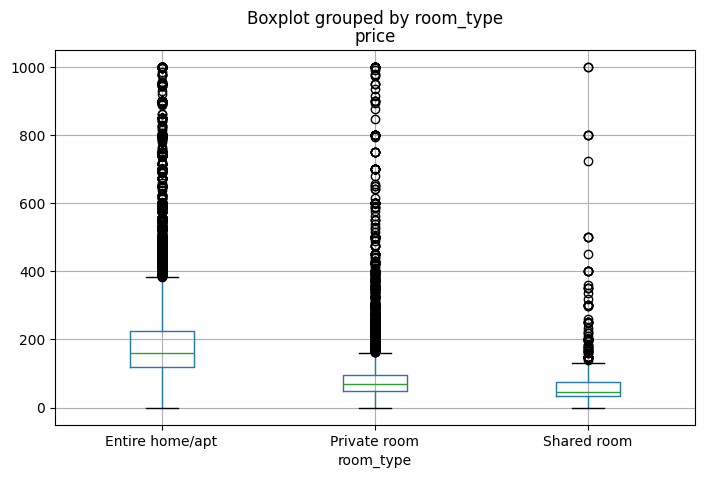

In [110]:
df[df["price"] <= 1000].boxplot(column="price", by="room_type", figsize=(8, 5))

**Finding:** The middle 50% of entire homes cost roughly USD 120 to USD 225, private rooms roughly USD 50 to USD 95 and shared rooms roughly USD 35 to USD 75, so the price differences between room types hold across most listings, not just at the median. Entire homes show the widest spread. All three room types have many high outliers, including some shared rooms priced at USD 500 or more, which seems implausible.

### 11.2 Price by neighbourhood group

In [111]:
df.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False)

,price
neighbourhood_group,
Manhattan,150.0
Brooklyn,90.0
Queens,75.0
Staten Island,75.0
Bronx,65.0


**Finding:** Median prices differ by neighbourhood group: USD 150 in Manhattan, USD 90 in Brooklyn, USD 75 in Queens and Staten Island, and USD 65 in the Bronx. The median listing in Manhattan costs about two-thirds more than in Brooklyn and more than twice as much as in the Bronx.

In [112]:
df.groupby(["neighbourhood_group", "room_type"])["price"].median().unstack()

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,100.0,53.5,40.0
Brooklyn,145.0,65.0,36.0
Manhattan,191.0,90.0,69.0
Queens,120.0,60.0,37.0
Staten Island,100.0,50.0,30.0


**Finding:** Manhattan has the highest median price within every room type (USD 191 for entire homes, USD 90 for private rooms, USD 69 for shared rooms), so its higher prices are not only due to having more entire homes: location matters on its own. Staten Island is among the cheapest within each room type, although its overall median equalled that of Queens, which suggests the overall figure was raised by a higher share of entire homes. Comparisons for shared rooms in the smaller neighbourhood groups are based on few listings and are less reliable. Overall, room type and location both appear to be associated with price, which supports including both in the regression model.

## 12. Correlations between numeric columns
Spearman correlation is used because most columns are strongly skewed. It compares the ranks of values rather than the values themselves, so extreme values have less influence. Values range from -1 to +1. Correlation shows association, not cause.

### 12.1 Correlation table and heatmap

In [113]:
df.drop(columns=["id", "host_id"]).corr(method="spearman", numeric_only=True).round(2)

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
latitude,1.00,0.04,0.14,0.02,-0.04,-0.02,0.00,-0.01
longitude,0.04,1.00,-0.44,-0.12,0.08,0.12,0.06,0.07
price,0.14,-0.44,1.00,0.10,-0.06,-0.02,-0.11,0.09
minimum_nights,0.02,-0.12,0.10,1.00,-0.17,-0.29,0.06,0.08
number_of_reviews,-0.04,0.08,-0.06,-0.17,1.00,0.71,0.06,0.24
reviews_per_month,-0.02,0.12,-0.02,-0.29,0.71,1.00,0.15,0.39
calculated_host_listings_count,0.00,0.06,-0.11,0.06,0.06,0.15,1.00,0.41
availability_365,-0.01,0.07,0.09,0.08,0.24,0.39,0.41,1.00


**Finding:** Among the numeric columns, longitude has the strongest relationship with price (-0.44): listings further east tend to be cheaper. Latitude shows a weak positive relationship (0.14), and all other numeric columns are only weakly related to price (between -0.11 and 0.10). Room type, which showed large price differences in section 11, is not included here as it is not numeric. number_of_reviews and reviews_per_month are strongly related (0.71), as they measure similar things, which is relevant for the regression. Hosts with more listings tend to have higher availability (0.41), and listings with longer minimum stays tend to receive fewer reviews per month (-0.29).

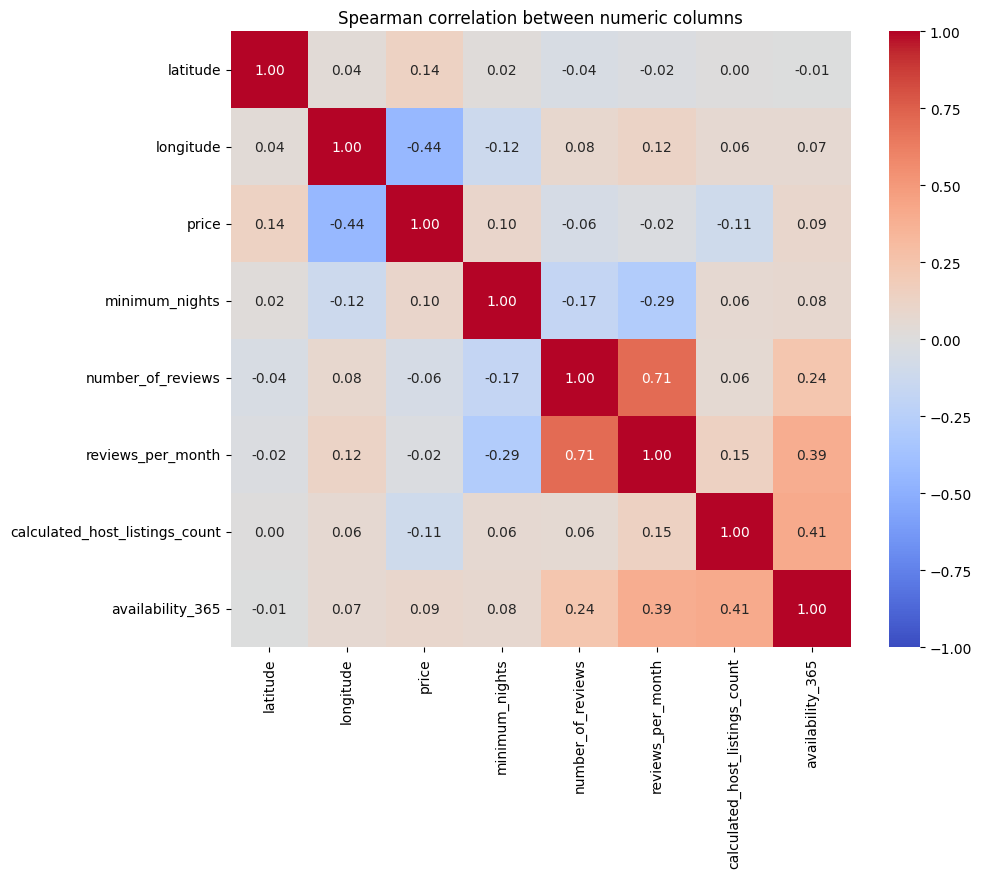

In [114]:
corr = df.drop(columns=["id", "host_id"]).corr(method="spearman", numeric_only=True)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation between numeric columns")
plt.show()

**Finding:** The heatmap shows the same correlations visually. The strongest relationships are between number_of_reviews and reviews_per_month (0.71) and between longitude and price (-0.44). Availability is moderately related to host listing count (0.41) and reviews per month (0.39). Most other pairs are weakly related, shown by pale colours.

### 12.2 Days since last review
last_review is a date stored as text, so it was not included in the correlations. Here it is converted into the number of days between each listing's last review and the latest review in the dataset (8 July 2019), as a measure of how recently a listing was active.

In [115]:
reference_date = pd.to_datetime(df["last_review"]).max()
df["days_since_last_review"] = (reference_date - pd.to_datetime(df["last_review"])).dt.days

In [116]:
df["days_since_last_review"].describe()

,days_since_last_review
count,38843.000000
mean,276.925418
std,413.916984
min,0.000000
25%,15.000000
50%,50.000000
75%,365.000000
max,3024.000000


**Finding:** Among the 38,843 listings with reviews, half were last reviewed within 50 days of the latest recorded review (8 July 2019), and 75% within a year. A smaller group has much longer intervals since their last recorded review, up to 3,024 days (over 8 years). The mean (277 days) is far above the median, so the distribution is right-skewed. Most listings with reviews received them relatively recently, while a smaller proportion have much longer intervals since their last recorded review.

In [117]:
df.drop(columns=["id", "host_id"]).corr(method="spearman", numeric_only=True)["days_since_last_review"].round(2).sort_values()

,days_since_last_review
reviews_per_month,-0.80
number_of_reviews,-0.50
availability_365,-0.47
calculated_host_listings_count,-0.15
longitude,-0.10
price,-0.02
latitude,0.04
minimum_nights,0.17
days_since_last_review,1.00


**Finding:** Among listings with reviews, days since last review is strongly related to reviews per month (-0.80), as both reflect review activity, so the two largely overlap. It is moderately related to availability (-0.47): listings that have not been reviewed for a long time tend to have fewer days available, which is consistent with the possibility that many listings with 0 days available are inactive, although this cannot be confirmed from the data. There is practically no relationship with price (-0.02), so listings without recent reviews are not systematically priced differently.

### 12.3 Price by longitude
Longitude has the strongest relationship with price. This scatterplot shows how log price changes from west to east.

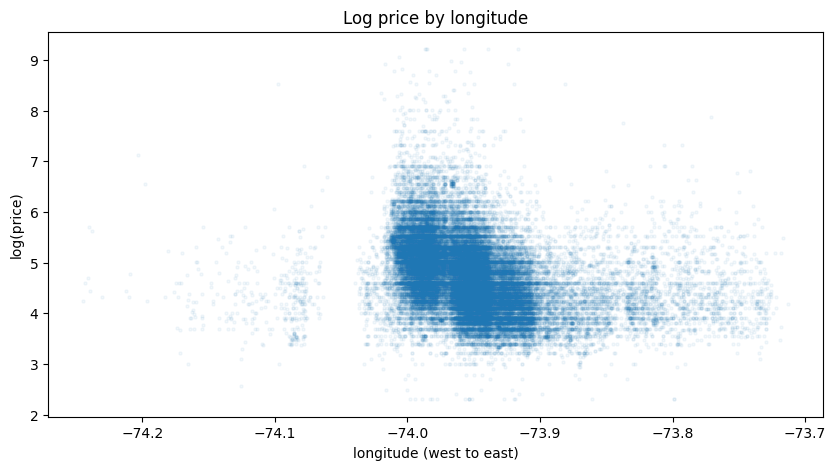

In [118]:
plt.figure(figsize=(10, 5))
plt.scatter(df[df["price"] > 0]["longitude"], np.log(df[df["price"] > 0]["price"]), alpha=0.05, s=5)
plt.xlabel("longitude (west to east)")
plt.ylabel("log(price)")
plt.title("Log price by longitude")
plt.show()

**Finding:** Most listings lie between longitude -74.02 and -73.90. Within this band, log price falls from west to east, from around 5 to 6 (roughly USD 150 to USD 400) to around 4 to 4.5 (roughly USD 55 to USD 90). However, the sparse listings further west (Staten Island, around -74.1 to -74.25) are also relatively cheap. Prices are therefore highest in a central band rather than simply in the west, which suggests that distance to the centre may describe the relationship better than longitude alone. The horizontal stripes reflect round prices.

### 12.4 Distance to Midtown
Section 12.3 suggested that prices are highest in a central band rather than simply in the west. This tests whether the distance to the centre describes the relationship with price better than longitude. Times Square (latitude 40.758896, longitude -73.985130; LatLong.net, no date) is used as the centre of Midtown. Distances are calculated in kilometres using scikit-learn's haversine_distances function, which gives the straight-line distance between two points on a sphere (scikit-learn developers, no date).

In [119]:
coords = np.radians(df[["latitude", "longitude"]].to_numpy())
center = np.radians([[40.758896, -73.985130]])
df["dist_midtown_km"] = haversine_distances(coords, center)[:, 0] * 6371

In [120]:
df["dist_midtown_km"].describe()

,dist_midtown_km
count,48895.000000
mean,7.135975
std,4.445869
min,0.032125
25%,3.857836
50%,6.405203
75%,9.467157
max,35.996613


**Finding:** Distances to Times Square range from 0.03 km to 36 km, which is plausible for New York City. Listings are concentrated fairly close to the centre: half are within 6.4 km and 75% within 9.5 km.

In [121]:
df[["price", "dist_midtown_km", "longitude"]].corr(method="spearman").round(2)

,price,dist_midtown_km,longitude
price,1.00,-0.45,-0.44
dist_midtown_km,-0.45,1.00,0.55
longitude,-0.44,0.55,1.00


**Finding:** Distance to Times Square shows a similar association with price to longitude (-0.45 vs -0.44): listings further from the centre tend to be cheaper. Correlation alone cannot show whether distance adds predictive value; this will be assessed by comparing models with and without it. Distance captures the pattern in all directions (including the cheaper listings on Staten Island in the far west) and is easier to interpret. Distance and longitude are moderately related to each other (0.55).

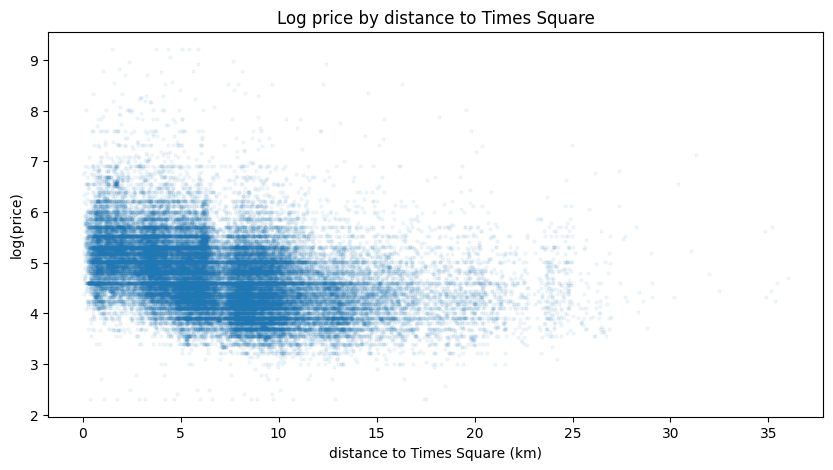

In [122]:
plt.figure(figsize=(10, 5))
plt.scatter(df[df["price"] > 0]["dist_midtown_km"], np.log(df[df["price"] > 0]["price"]), alpha=0.05, s=5)
plt.xlabel("distance to Times Square (km)")
plt.ylabel("log(price)")
plt.title("Log price by distance to Times Square")
plt.show()

**Finding:** Prices are highest within about 6 km of Times Square (log price mostly 4.5 to 6, roughly USD 90 to USD 400), drop noticeably between about 6 and 8 km, and stay at a lower, fairly flat level beyond about 10 km. The relationship is therefore not linear: prices fall mainly within the first 6 to 10 km and then level off. Prices still vary widely at every distance, so distance explains only part of the price. A linear model may need a transformed version of distance (such as its logarithm), while tree-based models can capture this shape directly.

### 12.5 Price on the map
Each listing is plotted at its location and coloured by its nightly price, to show where higher and lower prices are found. The colour scale is logarithmic and runs from USD 30 to USD 800 (roughly the 1st to 99th percentile); listings above USD 800 show the darkest colour, and listings priced at USD 0 are excluded. Listings are drawn in order of price, so higher-priced listings appear on top.

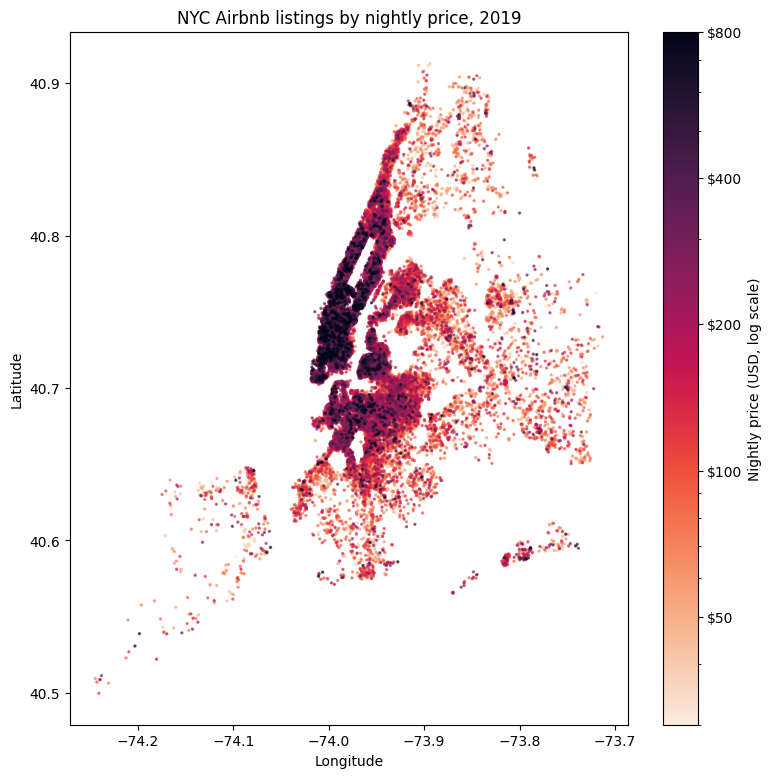

In [123]:
plot_df = df[df["price"] > 0].sort_values("price")

plt.figure(figsize=(9, 9))
points = plt.scatter(plot_df["longitude"], plot_df["latitude"], c=plot_df["price"],
                     cmap=sns.color_palette("rocket_r", as_cmap=True),
                     norm=LogNorm(vmin=30, vmax=800), s=2, alpha=0.6)
colorbar = plt.colorbar(points)
colorbar.solids.set_alpha(1)
colorbar.set_ticks([50, 100, 200, 400, 800])
colorbar.set_ticklabels(["$50", "$100", "$200", "$400", "$800"])
colorbar.set_label("Nightly price (USD, log scale)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("NYC Airbnb listings by nightly price, 2019")
plt.show()

**Finding:** Prices are highest in Manhattan, particularly its southern half, and in the parts of Brooklyn closest to Manhattan, where most listings appear in the darkest colours. Prices are generally lower in the outer parts of Brooklyn, Queens, the Bronx and Staten Island, although individual high-priced listings appear across the city. This matches the earlier findings on price by neighbourhood group (section 11.2) and distance to Times Square (section 12.4), and shows the pattern in a form that is easy to read without technical knowledge. As dots overlap in dense areas, the map shows where prices are high, but not exactly how many listings are at each price.

## 13. Single-listing and multi-listing hosts
Our question focuses on types of hosts. This section compares listings from hosts with one listing and hosts with several listings, to see whether they differ in room type, availability, minimum stay and price. In the tables below, False means a host with one listing and True a host with several listings.

### 13.1 Room type

In [124]:
pd.crosstab(df["calculated_host_listings_count"] > 1, df["room_type"], normalize="index").round(2)

room_type,Entire home/apt,Private room,Shared room
calculated_host_listings_count,,,
False,0.59,0.40,0.01
True,0.39,0.57,0.04


**Finding:** Listings from single-listing hosts are mostly entire homes (59%) and less often private rooms (40%). Listings from multi-listing hosts are mostly private rooms (57%), with fewer entire homes (39%) and more shared rooms (4% vs 1%). This suggests that many multi-listing hosts rent out several rooms, while single-listing hosts more often rent out a whole home. Room type mix is therefore a clear difference between host types.

### 13.2 Availability, minimum stay and price

In [125]:
df.groupby(df["calculated_host_listings_count"] > 1)[["availability_365", "minimum_nights", "price"]].median()

,availability_365,minimum_nights,price
calculated_host_listings_count,,,
False,6.0,3.0,119.0
True,179.0,2.0,93.0


**Finding:** The clearest difference between host types is availability: listings from single-listing hosts have a median of only 6 days available per year, compared with 179 days for multi-listing hosts. This suggests different hosting practices: listings from single-listing hosts are available on far fewer days than those from multi-listing hosts, although listing count and availability do not establish whether a host is professional. Minimum stays are similar (median 3 vs 2 nights). Multi-listing hosts' listings have a lower median price (USD 93 vs USD 119), but as they are more often private rooms, this difference may be due to room type rather than host type.

### 13.3 Price by host type within each room type

In [126]:
df.groupby([df["calculated_host_listings_count"] > 1, "room_type"])["price"].median().unstack()

room_type,Entire home/apt,Private room,Shared room
calculated_host_listings_count,,,
False,155.0,70.0,65.0
True,175.0,67.0,38.0


**Finding:** Within each room type, the price difference between host types looks different from the overall comparison. For entire homes, multi-listing hosts charge more (median USD 175 vs USD 155). For private rooms, prices are almost the same (USD 67 vs USD 70). For shared rooms, multi-listing hosts charge less (USD 38 vs USD 65), although this is based on few listings from single-listing hosts. The lower overall median for multi-listing hosts (section 13.2) is therefore mainly due to their higher share of private rooms, not lower prices for comparable listings. Host type and room type should be considered together.

## 14. Summary

### 14.1 Key findings
- **Data quality:** The dataset has 48,895 listings from 37,457 hosts, with no duplicates, consistent categories and no placeholder text. The 10,052 missing values in last_review and reviews_per_month belong exactly to listings without reviews. name (16) and host_name (21) have a few missing values.
- **Price:** Prices are strongly right-skewed: the median is USD 106 and 98% of listings cost between USD 30 and USD 799, but prices reach USD 10,000. 11 listings are priced at USD 0, which is most likely an error. The most expensive listings include implausible cases, such as private rooms at USD 6,500 to USD 10,000 and a repeated price of USD 9,999. On a log scale, prices are roughly bell-shaped.
- **Room type and location:** Both are clearly associated with price. Median prices are USD 160 for entire homes, USD 70 for private rooms and USD 45 for shared rooms. Manhattan has the highest median price within every room type. Distance to Times Square (-0.45) and longitude (-0.44) show the strongest correlations with price among the numeric columns; the scatter plot suggests that prices generally decline with distance from Times Square, with a less pronounced decline beyond about 10 km, so the relationship does not appear to be linear.
- **Neighbourhoods:** Listings are concentrated: the 10 largest of 221 neighbourhoods hold about 48% of listings, while 106 neighbourhoods have fewer than 30.
- **Minimum stay:** 75% of listings require 5 nights or fewer, but a distinct group requires about a month (30 nights is the fourth most common value). Long-stay listings appear to be priced per night. 14 listings require more than a year, often with placeholder-like values (999, 500).
- **Availability:** 17,533 listings (about 36%) have 0 days available. This does not have a single meaning: some have recent reviews, while many have only old reviews or none.
- **Reviews:** number_of_reviews and reviews_per_month (0.71), and days since last review and reviews_per_month (-0.80), largely overlap. Very high values of reviews_per_month appear plausible.
- **Hosts:** 86% of hosts have a single listing, while 115 hosts have 10 or more. Measured by listings, the picture differs: single-listing hosts hold 66.1% of listings, hosts with 2 to 9 listings 27.4% and hosts with 10 or more 6.5%, so results differ depending on whether they are reported per host or per listing. Listings from multi-listing hosts are more often private rooms (57% vs 40%) and available on far more days (median 179 vs 6). Within each room type, price differences between host types are small or mixed, so host type and room type need to be considered together.

### 14.2 Usefulness of each column for our question

| Column | Proposed use | Reason |
|---|---|---|
| id | Identifier only | Not meaningful as a feature |
| name | Not used in the models | Free text (listing title) |
| host_id | Building the host table; grouping for the train/test split | Identifies hosts, not meaningful as a number |
| host_name | Drop | Personal data, not needed |
| neighbourhood_group | Feature | Clear price differences, also within room types |
| neighbourhood | Describing results; possible feature if tested | 221 values, many with very few listings; would need grouping if used in a model |
| latitude, longitude | Features | Location is associated with price |
| room_type | Key feature; host table | Strongest price differences |
| price | Target of the regression | Not used to build the host groups |
| minimum_nights | Feature; host table | Distinguishes short and month-long stays |
| number_of_reviews | Comparison after modelling | Overlaps with reviews_per_month; kept out of the models |
| last_review | Converted to days since last review | Measures review recency |
| reviews_per_month | Comparison with price deviations | Kept out of the models, as agreed by the team |
| calculated_host_listings_count | Feature; host table | Consistent with the data; separates host types |
| availability_365 | Feature; host table | Clear difference between host types; 0 is ambiguous |
| dist_midtown_km (new) | Feature | Captures the location pattern in all directions |
| days_since_last_review (new) | Supporting variable | Helps interpret availability and review activity |

### 14.3 Limitations
- The data is a single snapshot (latest recorded review: 8 July 2019), so it shows no changes over time, and the market may have changed since.
- Prices are advertised nightly prices, not prices actually paid, and important price factors such as size, amenities, photos and quality are not included. As a result, later deviations from model-predicted prices should be read as differences from the estimate, not necessarily as incorrect pricing.
- Demand can only be estimated indirectly: not every guest leaves a review, and 0 days available can mean booked, blocked or inactive.
- Individual extreme values (for example very high prices or minimum stays) cannot be verified, so rules for handling them are judgement calls.
- Comparisons for small groups (shared rooms, the Bronx, Staten Island) are based on few listings and are less reliable. Correlations and median comparisons show associations, not causes.
- The whole dataset was explored before modelling, including listings that will later be used for evaluation, which introduces a potential risk of data snooping: some cleaning and feature choices may have been influenced by data later used to evaluate the models. To limit further bias, later preprocessing and model choices should be made within the training data of each cross-validation round only.

### 14.4 Proposed cleaning rules (for team discussion)
1. **Remove the 11 listings priced at USD 0**, as their true price is unknown.
2. **Very high prices:** keep listings with positive prices, including very high ones, and add a yes/no column marking listings priced above USD 1,000 (239 listings). Some very high prices may be errors, but others may be genuine deviations, which our question aims to study. The regression can test whether excluding them changes prediction accuracy and which host types show large deviations (sensitivity analysis). As this column is derived from price (the target), it is a diagnostic variable only and must not be used as a model input.
3. **Very long minimum stays:** remove listings requiring more than 365 nights (14 listings), as these are implausible for short-term rentals and often look like placeholder values. Month-long stays are kept, as they form a genuine group.
4. **0 days available:** keep these listings and add a yes/no column marking them, as the data cannot show which of them are inactive. Removing them would lose about a third of the data. As the team plans to compare price deviations with review activity, listings should not be excluded based on their review history in the main analysis; the effect of excluding possibly inactive listings can be tested separately.
5. **Missing review values:** fill reviews_per_month with 0, as section 4.1 showed these listings have no reviews. Convert last_review to a date and add days_since_last_review, leaving it empty for listings without reviews, with a yes/no column marking whether a listing has reviews.
6. **Columns:** drop host_name. Keep name for reference only.
7. **New columns:** add dist_midtown_km and days_since_last_review. days_since_last_review and the has-reviews column (rule 5) are supporting variables: they are not target-derived, but they are excluded from the regression, in line with the team's decision to keep review information out of the models and compare it with price deviations afterwards.
8. **Host table:** create one row per host from all 48,895 original listings, independently of the price-related cleaning, as a host's characteristics do not depend on whether a listing's price is valid. Columns: number of listings (the original calculated_host_listings_count), average availability, share of listings with 0 days available, share of entire homes, median minimum stay and number of neighbourhood groups. As 0 days available is ambiguous (rule 4), its share is included separately, so the clustering can distinguish hosts with closed calendars from hosts with generally low availability. For the host-level median minimum stay, values above 365 nights are treated as missing, because they may represent errors or non-standard rentals. The listings themselves remain in the host table, preserving the original portfolio information. Missing host-level medians will be handled during clustering preprocessing. Price and review columns are not included. The host clustering is initially descriptive and independent of the regression model.
9. **Left to the modelling notebooks:** decisions about log-transforming price, scaling numerical features and encoding categorical variables. Preprocessing steps that learn from the data will be fitted on training data only, to prevent leakage.

## References
Dgomonov (2019) *New York City Airbnb open data* [Data set]. Kaggle. Available at: https://www.kaggle.com/dgomonov/new-york-city-airbnb-open-data (Accessed: 4 November 2026).

LatLong.net (no date) *Times Square, NYC, USA*. Available at: https://www.latlong.net/place/times-square-nyc-usa-7560.html (Accessed: 4 November 2026).

New York City Department of City Planning (2014) *New York City counties, 2014*. Columbia University Libraries. Available at: https://geodata.libraries.mit.edu/record/gisogm:edu.columbia:8efcf8ed1456 (Accessed: 3 November 2026).

scikit-learn developers (no date) *sklearn.metrics.pairwise.haversine_distances*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.haversine_distances.html (Accessed: 4 November 2026).